# Loan Portfolio Analysis - Exploratory Data Analysis

A step-by-step EDA of the loan portfolio, customer profile, repayment records, and branch reference data. The workflow covers loading and validation, descriptive statistics, feature engineering, univariate and comparative analysis, visualizations, correlations, and exportable charts.

**Data files:** `loan.csv`, `customers.csv`, `payments.csv`, and `branches.csv`.

**Important data-structure note:** loan and customer records can be joined one-to-one using their shared customer key. Payments can be attached by loan key. `branches.csv` has no loan/customer key, so it is profiled separately and is not attributed to individual loans.

## 1. Import Libraries and Load the Data

The first code cell imports the analysis libraries, reads the four CSV files, parses payment dates, and constructs the loan-level analysis table with validated joins.

In [13]:
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 6)

DATA_DIR = Path.cwd()
required_files = ['loan.csv', 'customers.csv', 'payments.csv', 'branches.csv']
missing_files = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(f'Missing data files in {DATA_DIR}: {missing_files}')

loan = pd.read_csv(DATA_DIR / 'loan.csv')
customers = pd.read_csv(DATA_DIR / 'customers.csv')
payment = pd.read_csv(DATA_DIR / 'payments.csv', parse_dates=['payment_date'])
branches = pd.read_csv(DATA_DIR / 'branches.csv')
loan_customer = loan.merge(customers, on='customer_id', how='left', validate='one_to_one', indicator='_customer_merge')
loan_analysis = loan_customer.merge(payment, on='loan_id', how='left', validate='one_to_one', indicator='_payment_merge')

print(f'Loaded loans: {loan.shape}; customers: {customers.shape}; payments: {payment.shape}; branches: {branches.shape}')
print(f'Loan-level analysis table: {loan_analysis.shape}')
print(f'Loans without a matching customer: {(loan_analysis["_customer_merge"] != "both").sum()}')
print(f'Loans without a payment record: {(loan_analysis["_payment_merge"] != "both").sum()}')
print('Branch data remains separate because no branch key exists in the loan or customer tables.')

Loaded loans: (52899, 7); customers: (52899, 7); payments: (52898, 5); branches: (52899, 3)
Loan-level analysis table: (52899, 19)
Loans without a matching customer: 0
Loans without a payment record: 1
Branch data remains separate because no branch key exists in the loan or customer tables.


## 2. Basic Data Inspection and Preprocessing

Inspect representative records, table dimensions, column types, descriptive statistics, missing values, category distributions, and duplicate records before interpreting the portfolio.

In [14]:
tables = {
    'loan': loan,
    'customers': customers,
    'payments': payment,
    'branches': branches
}

for table_name, table in tables.items():
    print(f'\n{"=" * 80}\n{table_name.upper()} - FIRST FIVE ROWS\n{"=" * 80}')
    display(table.head())
    print(f'{table_name} shape: {table.shape}')
    print(f'Columns: {table.columns.tolist()}')
    print(f'\n{table_name} data types:')
    display(table.dtypes.rename('data_type').to_frame())
    print(f'{table_name} numeric summary:')
    display(table.describe().T.round(2))
    print(f'{table_name} duplicate full rows: {table.duplicated().sum()}')

print('\nLoan records - last five rows:')
display(loan.tail())
print('\nReproducible random sample of five loans:')
display(loan.sample(min(5, len(loan)), random_state=42))


LOAN - FIRST FIVE ROWS


,loan_id,customer_id,loan_type,loan_amount,interest_rate,loan_term_months,loan_status
0,500001,100001,Education Loan,541460,13.57,84,Current
1,500002,100002,Vehicle Loan,1450582,8.03,48,Closed
2,500003,100003,Personal Loan,565572,14.67,24,Current
3,500004,100004,Personal Loan,625816,21.21,12,Current
4,500005,100005,Personal Loan,402784,10.90,24,Current


loan shape: (52899, 7)
Columns: ['loan_id', 'customer_id', 'loan_type', 'loan_amount', 'interest_rate', 'loan_term_months', 'loan_status']

loan data types:


,data_type
loan_id,int64
customer_id,int64
loan_type,str
loan_amount,int64
interest_rate,float64
loan_term_months,int64
loan_status,str


loan numeric summary:


...

,count,mean,std,min,25%,50%,75%,max
branch_id,52899.0,15.45,8.66,1.0,8.0,15.0,23.0,30.0


branches duplicate full rows: 52868

Loan records - last five rows:


,loan_id,customer_id,loan_type,loan_amount,interest_rate,loan_term_months,loan_status
52894,552895,152895,Personal Loan,460119,10.38,12,Current
52895,552896,152896,Personal Loan,838019,23.10,12,Closed
52896,552897,152897,Personal Loan,420407,23.69,12,Default
52897,552898,152898,Business Loan,4525800,16.99,36,Default
52898,552899,152899,Personal Loan,709717,16.16,60,Current



Reproducible random sample of five loans:


,loan_id,customer_id,loan_type,loan_amount,interest_rate,loan_term_months,loan_status
15397,515398,115398,Home Loan,6246872,9.16,60,Closed
28053,528054,128054,Business Loan,3619349,15.82,48,Closed
3751,503752,103752,Business Loan,1196542,12.58,36,Current
18399,518400,118400,Business Loan,2064093,16.40,36,Closed
32834,532835,132835,Personal Loan,507304,10.91,60,Default


## 3. Data Quality and Relationship Checks

Check key uniqueness, missingness, join coverage, category balance, and repeated branch rows. These checks determine which comparisons and joins are defensible.

In [15]:
missing_summary = pd.DataFrame({
    'missing_count': loan_analysis.isna().sum(),
    'missing_percent': (loan_analysis.isna().mean() * 100).round(2),
    'unique_values': loan_analysis.nunique(dropna=False),
    'data_type': loan_analysis.dtypes.astype(str)
}).sort_values('missing_count', ascending=False)
print('Missingness and cardinality in the loan-level table:')
display(missing_summary)

key_checks = pd.DataFrame({
    'check': [
        'loan_id unique in loan table',
        'customer_id unique in customer table',
        'payment_id unique in payment table',
        'loan_id unique in payment table',
        'loan rows without customer match',
        'loans without payment record',
        'duplicate loan rows',
        'duplicate customer rows',
        'duplicate payment rows',
        'duplicate branch rows'
    ],
    'result': [
        loan['loan_id'].is_unique,
        customers['customer_id'].is_unique,
        payment['payment_id'].is_unique,
        payment['loan_id'].is_unique,
        int((loan_analysis['_customer_merge'] != 'both').sum()),
        int((loan_analysis['_payment_merge'] != 'both').sum()),
        int(loan.duplicated().sum()),
        int(customers.duplicated().sum()),
        int(payment.duplicated().sum()),
        int(branches.duplicated().sum())
    ]
})
display(key_checks)

print('Loan type distribution:')
display(loan['loan_type'].value_counts(dropna=False).rename('count').to_frame())
print('Loan status distribution:')
display(loan['loan_status'].value_counts(dropna=False).rename('count').to_frame())
print('Payment status distribution:')
display(payment['payment_status'].value_counts(dropna=False).rename('count').to_frame())

branch_profile = (branches.groupby('branch_id')
                  .agg(branch_name=('branch_name', 'nunique'),
                       city=('city', 'nunique'),
                       source_rows=('branch_id', 'size'))
                  .sort_values('source_rows', ascending=False))
print('Branch source rows by branch ID (not linked to loans):')
display(branch_profile.head(10))

Missingness and cardinality in the loan-level table:


,missing_count,missing_percent,unique_values,data_type
payment_status,1,0.0,5,str
amount_paid,1,0.0,49674,float64
payment_date,1,0.0,1827,datetime64[us]
payment_id,1,0.0,52899,float64
loan_type,0,0.0,5,str
loan_id,0,0.0,52899,int64
customer_id,0,0.0,52899,int64
loan_amount,0,0.0,52508,int64
interest_rate,0,0.0,1701,float64
loan_term_months,0,0.0,11,int64


,check,result
0,loan_id unique in loan table,True
1,customer_id unique in customer table,True
2,payment_id unique in payment table,True
3,loan_id unique in payment table,True
4,loan rows without customer match,0
5,loans without payment record,1
6,duplicate loan rows,0
7,duplicate customer rows,0
8,duplicate payment rows,0
9,duplicate branch rows,52868


Loan type distribution:


,count
loan_type,
Personal Loan,15991
Home Loan,11546
Vehicle Loan,10417
Business Loan,9639
Education Loan,5306


...

,count
loan_status,
Current,32840
Closed,15384
Default,4675


Payment status distribution:


,count
payment_status,
Paid,40260
Pending,6227
Partial,3526
Missed,2885


Branch source rows by branch ID (not linked to loans):


,branch_name,city,source_rows
branch_id,,,
1,1,1,1839
8,1,2,1836
4,1,1,1825
5,1,1,1822
23,1,1,1798
2,1,1,1795
19,1,1,1795
22,1,1,1793
24,1,1,1784


## 4. Feature Engineering

Create interpretable portfolio measures for analysis: loan-to-income ratio, estimated amortizing monthly payment and total interest, plus age, credit-score, and loan-size bands. Payment estimates are illustrative and do not include fees or lender-specific terms.

In [16]:
loan_analysis['loan_to_income_ratio'] = (
    loan_analysis['loan_amount'] / loan_analysis['annual_income'].replace(0, np.nan)
)
monthly_rate = loan_analysis['interest_rate'] / 100 / 12
term = loan_analysis['loan_term_months']
compound_factor = (1 + monthly_rate) ** term
loan_analysis['estimated_monthly_payment'] = np.where(
    monthly_rate.eq(0),
    loan_analysis['loan_amount'] / term,
    loan_analysis['loan_amount'] * monthly_rate * compound_factor / (compound_factor - 1)
)
loan_analysis['estimated_total_repayment'] = (
    loan_analysis['estimated_monthly_payment'] * term
)
loan_analysis['estimated_total_interest'] = (
    loan_analysis['estimated_total_repayment'] - loan_analysis['loan_amount']
)
loan_analysis['age_group'] = pd.cut(
    loan_analysis['age'],
    bins=[0, 25, 35, 45, 55, 65, np.inf],
    labels=['Under 25', '25-34', '35-44', '45-54', '55-64', '65+'],
    right=False
)
loan_analysis['credit_score_band'] = pd.cut(
    loan_analysis['credit_score'],
    bins=[0, 580, 670, 740, 800, np.inf],
    labels=['Below 580', '580-669', '670-739', '740-799', '800+'],
    right=False
)
loan_analysis['loan_amount_quartile'] = pd.qcut(
    loan_analysis['loan_amount'], q=4, duplicates='drop'
)

engineered_columns = [
    'loan_to_income_ratio', 'estimated_monthly_payment',
    'estimated_total_interest', 'age_group', 'credit_score_band',
    'loan_amount_quartile'
]
print('Derived feature summary:')
display(loan_analysis[engineered_columns].describe(include='all').T)

Derived feature summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
loan_to_income_ratio,52899.0,NaN,NaN,NaN,3.78733,5.287951,0.013035,0.774742,1.918088,4.621959,83.172222
estimated_monthly_payment,52899.0,NaN,NaN,NaN,46802.630289,51449.104869,1020.473835,16479.885893,31685.656494,59912.360135,462768.586578
estimated_total_interest,52899.0,NaN,NaN,NaN,1139324.308616,1936708.623476,2944.526166,139954.1465,374369.634826,1182834.19948,16110379.19136
age_group,52899,6,55-64,10711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_score_band,52899,5,670-739,18540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amount_quartile,52899,4,"(50002.999, 569999.5]",13225,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Loan Portfolio Distributions

Start with univariate questions: which products and statuses dominate, how large are loans, and how are interest rates and terms distributed? Counts and amounts are both shown because a high-volume segment is not necessarily the largest exposure.

Numeric portfolio and borrower summary:


,count,mean,std,min,25%,50%,75%,max
loan_amount,52899.0,1980328.95,1901955.79,50003.0,569999.50,1290305.00,2696949.00,7999806.0
interest_rate,52899.0,13.25,4.19,7.0,10.01,12.28,15.81,24.0
loan_term_months,52899.0,76.80,67.88,12.0,36.00,60.00,84.00,300.0
age,52899.0,45.56,14.46,21.0,33.00,46.00,58.00,70.0
annual_income,52899.0,804351.74,582035.63,90000.0,418866.00,649443.00,1012752.50,6000000.0
credit_score,52899.0,689.90,74.96,378.0,639.00,690.00,741.00,900.0



loan_type distribution:


,count
loan_type,
Personal Loan,15991
Home Loan,11546
Vehicle Loan,10417
Business Loan,9639
Education Loan,5306



loan_status distribution:


...

,count
age_group,
55-64,10711
35-44,10559
45-54,10554
25-34,10375
65+,6363
Under 25,4337



credit_score_band distribution:


,count
credit_score_band,
670-739,18540
580-669,17034
740-799,9716
800+,3826
Below 580,3783



Portfolio exposure by loan type:


,loan_count,total_principal,average_principal,average_rate,portfolio_share_percent
loan_type,,,,,
Home Loan,11546,50909434227,4409270.24,9.24,48.60
Business Loan,9639,25564553986,2652199.81,14.51,24.40
Vehicle Loan,10417,13828898564,1327531.78,12.01,13.20
Personal Loan,15991,7568900128,473322.50,17.01,7.23
Education Loan,5306,6885633965,1297707.12,10.78,6.57


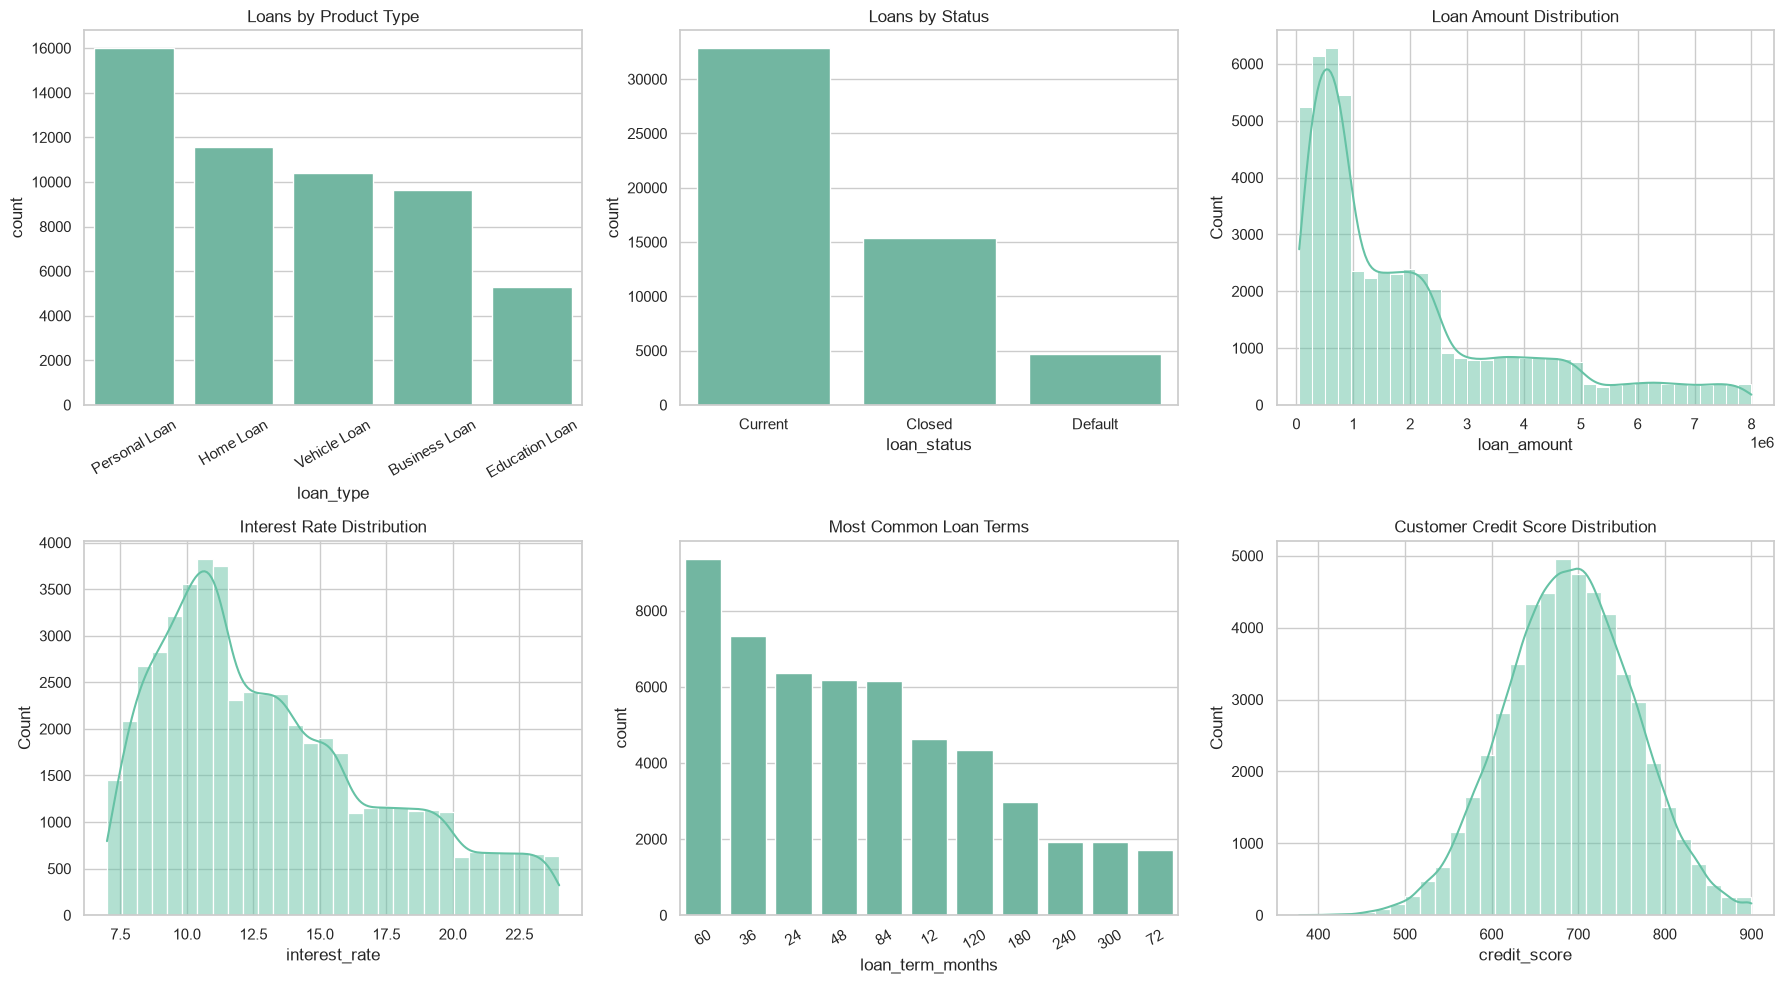

In [17]:
loan_numeric = [
    'loan_amount', 'interest_rate', 'loan_term_months',
    'age', 'annual_income', 'credit_score'
]
print('Numeric portfolio and borrower summary:')
display(loan_analysis[loan_numeric].describe().T.round(2))

for column in ['loan_type', 'loan_status', 'gender', 'employment_type', 'age_group', 'credit_score_band']:
    print(f'\n{column} distribution:')
    display(loan_analysis[column].value_counts(dropna=False).rename('count').to_frame())

portfolio_by_type = (loan_analysis.groupby('loan_type', observed=True)
                     .agg(loan_count=('loan_id', 'count'),
                          total_principal=('loan_amount', 'sum'),
                          average_principal=('loan_amount', 'mean'),
                          average_rate=('interest_rate', 'mean'))
                     .sort_values('total_principal', ascending=False))
portfolio_by_type['portfolio_share_percent'] = (
    portfolio_by_type['total_principal'] / loan_analysis['loan_amount'].sum() * 100
)
print('\nPortfolio exposure by loan type:')
display(portfolio_by_type.round(2))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.countplot(data=loan_analysis, x='loan_type', order=loan_analysis['loan_type'].value_counts().index, ax=axes[0, 0])
axes[0, 0].set_title('Loans by Product Type')
axes[0, 0].tick_params(axis='x', rotation=30)
sns.countplot(data=loan_analysis, x='loan_status', order=loan_analysis['loan_status'].value_counts().index, ax=axes[0, 1])
axes[0, 1].set_title('Loans by Status')
sns.histplot(data=loan_analysis, x='loan_amount', bins=35, kde=True, ax=axes[0, 2])
axes[0, 2].set_title('Loan Amount Distribution')
sns.histplot(data=loan_analysis, x='interest_rate', bins=30, kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Interest Rate Distribution')
sns.countplot(data=loan_analysis, x='loan_term_months', order=loan_analysis['loan_term_months'].value_counts().index[:12], ax=axes[1, 1])
axes[1, 1].set_title('Most Common Loan Terms')
axes[1, 1].tick_params(axis='x', rotation=30)
sns.histplot(data=loan_analysis, x='credit_score', bins=30, kde=True, ax=axes[1, 2])
axes[1, 2].set_title('Customer Credit Score Distribution')
plt.tight_layout()
plt.show()

## 6. Customer and Borrower Profile

Compare customer demographics, income, and credit scores across employment groups, age bands, and loan statuses. These are descriptive comparisons, not evidence that a demographic characteristic causes a lending outcome.

Borrower profile by employment type and gender:


customer_count  average_income  median_income  \
employment_type gender                                                  
Salaried        Male             14082       804771.39       647927.0   
                Female           13115       814985.01       650995.0   
Self-Employed   Male              5845       809094.42       659229.0   
                Female            5643       794136.01       645033.0   
Business Owner  Male              4424       801429.64       654767.0   
                Female            4029       797557.53       644683.0   
Retired         Male              1967       767632.55       633208.0   
                Female            1771       787165.27       637420.0   
Unemployed      Male               786       840767.36       669529.0   
                Female             737       798483.04       664380.0   
Salaried        Other              263       820829.91       648782.0   
Self-Employed   Other               94       782832.90       593375.5   
Business Owner  Other               84       855925.63       718884.0   
Retired         Other               42       805251.31       662435.5   
Unemployed      Other               17       601289.12       438940.0   

                        average_credit_score  average_loan_amount  
employment_type gender                                             
Salaried        Male                  689.67           1982453.55  
                Female                689.94           1979975.39  
Self-Employed   Male                  689.46           1965014.65  
                Female                690.54           1963424.22  
Business Owner  Male                  689.76           2011266.10  
                Female                690.91           2017201.91  
Retired         Male                  690.81           1904466.14  
                Female                689.13           1963642.31  
Unemployed      Male                  689.99           1996057.85  
                Female                691.01           1985391.67  
Salaried        Other                 684.02           2059933.51  
Self-Employed   Other                 673.06           1911511.12  
Business Owner  Other                 693.81           2280203.17  
Retired         Other                 690.79           2121388.02  
Unemployed      Other                 675.29           1468289.53

Loan characteristics by status:


,loan_count,average_loan_amount,median_loan_amount,average_interest_rate,average_credit_score,average_loan_to_income
loan_status,,,,,,
Current,32840,1969280.69,1274660.5,13.23,693.79,3.69
Closed,15384,1935854.63,1246398.5,13.29,693.52,3.68
Default,4675,2204289.91,1589895.0,13.27,650.69,4.86


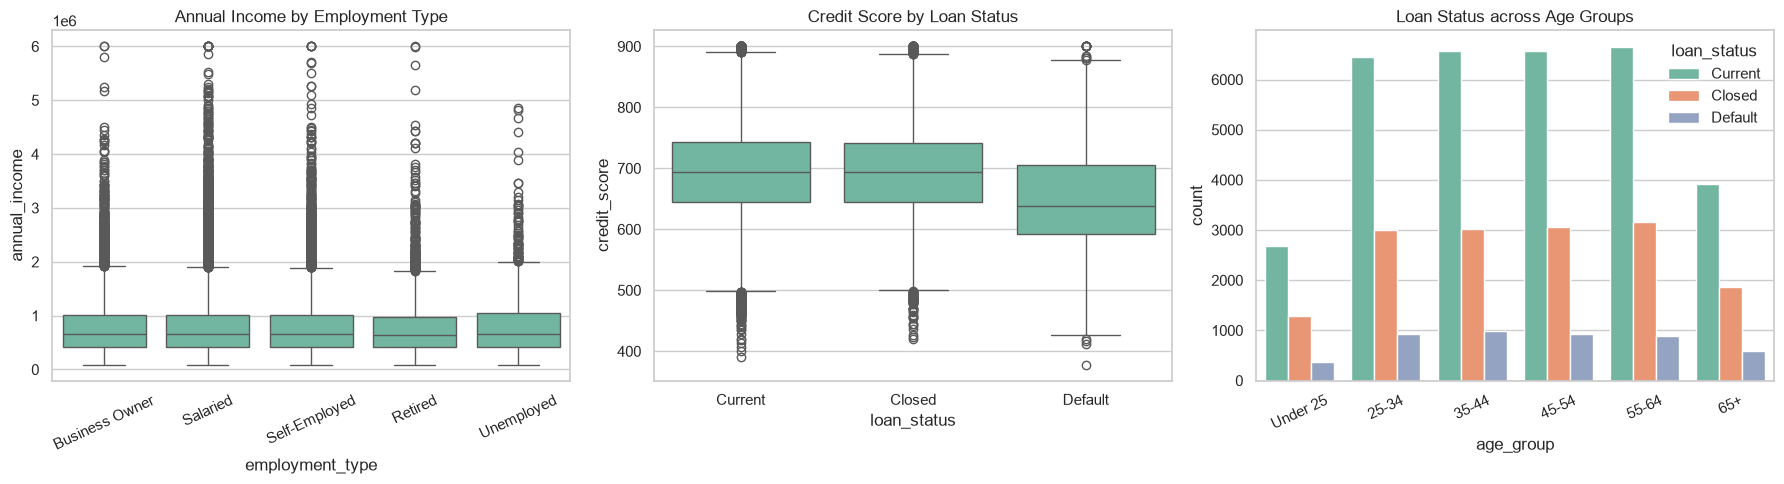

In [18]:
borrower_profile = (loan_analysis.groupby(['employment_type', 'gender'], observed=True)
                   .agg(customer_count=('customer_id', 'nunique'),
                        average_income=('annual_income', 'mean'),
                        median_income=('annual_income', 'median'),
                        average_credit_score=('credit_score', 'mean'),
                        average_loan_amount=('loan_amount', 'mean'))
                   .sort_values('customer_count', ascending=False))
print('Borrower profile by employment type and gender:')
display(borrower_profile.round(2))

status_profile = (loan_analysis.groupby('loan_status', observed=True)
                  .agg(loan_count=('loan_id', 'count'),
                       average_loan_amount=('loan_amount', 'mean'),
                       median_loan_amount=('loan_amount', 'median'),
                       average_interest_rate=('interest_rate', 'mean'),
                       average_credit_score=('credit_score', 'mean'),
                       average_loan_to_income=('loan_to_income_ratio', 'mean'))
                  .sort_values('loan_count', ascending=False))
print('Loan characteristics by status:')
display(status_profile.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=loan_analysis, x='employment_type', y='annual_income', ax=axes[0])
axes[0].set_title('Annual Income by Employment Type')
axes[0].tick_params(axis='x', rotation=25)
sns.boxplot(data=loan_analysis, x='loan_status', y='credit_score', ax=axes[1])
axes[1].set_title('Credit Score by Loan Status')
sns.countplot(data=loan_analysis, x='age_group', hue='loan_status', ax=axes[2])
axes[2].set_title('Loan Status across Age Groups')
axes[2].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

## 7. Payment Performance

Explore payment status, amount paid, and the observed payment-date pattern. The source has at most one payment row per loan, so this section describes the supplied payment snapshot rather than a full installment-by-installment history.

Payment outcomes and amounts:


,payment_records,average_amount_paid,median_amount_paid,total_amount_paid,record_share_percent
payment_status,,,,,
Paid,40260,27134.90,14090.80,1.092451e+09,76.11
Pending,6227,26271.68,14263.22,1.635937e+08,11.77
Partial,3526,22250.82,11270.11,7.845641e+07,6.67
Missed,2885,0.00,0.00,0.000000e+00,5.45


Payment status mix within each loan status (percent):


payment_status,Missed,Paid,Partial,Pending
loan_status,,,,
Closed,0.0,82.8,4.7,12.5
Current,0.0,81.9,5.0,13.1
Default,61.7,13.4,24.9,0.0


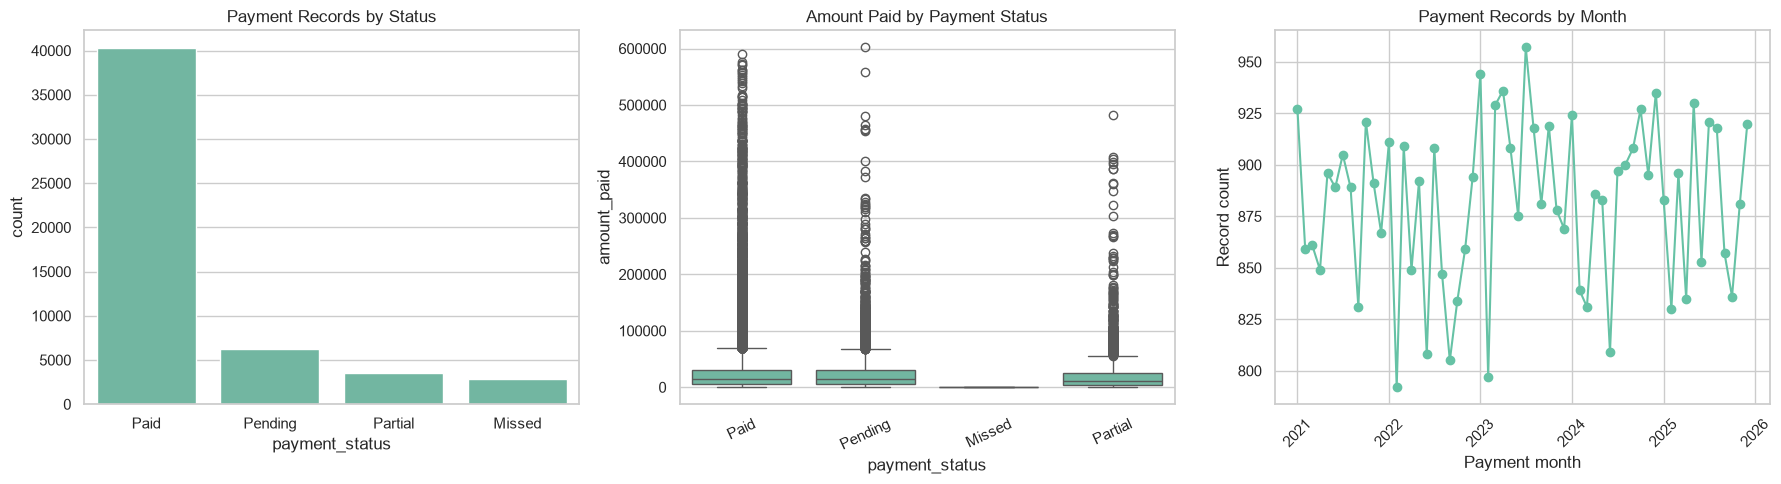

In [19]:
payment_summary = (payment.groupby('payment_status', observed=True)
                   .agg(payment_records=('payment_id', 'count'),
                        average_amount_paid=('amount_paid', 'mean'),
                        median_amount_paid=('amount_paid', 'median'),
                        total_amount_paid=('amount_paid', 'sum'))
                   .sort_values('payment_records', ascending=False))
payment_summary['record_share_percent'] = (
    payment_summary['payment_records'] / len(payment) * 100
)
print('Payment outcomes and amounts:')
display(payment_summary.round(2))

payment_by_loan_status = pd.crosstab(
    loan_analysis['loan_status'],
    loan_analysis['payment_status'],
    normalize='index'
).mul(100)
print('Payment status mix within each loan status (percent):')
display(payment_by_loan_status.round(1))

monthly_payments = (payment.dropna(subset=['payment_date'])
                    .assign(payment_month=lambda frame: frame['payment_date'].dt.to_period('M').dt.to_timestamp())
                    .groupby('payment_month')
                    .agg(payment_count=('payment_id', 'count'),
                         amount_paid=('amount_paid', 'sum'))
                    .reset_index())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=payment, x='payment_status', order=payment['payment_status'].value_counts().index, ax=axes[0])
axes[0].set_title('Payment Records by Status')
sns.boxplot(data=payment, x='payment_status', y='amount_paid', ax=axes[1])
axes[1].set_title('Amount Paid by Payment Status')
axes[1].tick_params(axis='x', rotation=25)
axes[2].plot(monthly_payments['payment_month'], monthly_payments['payment_count'], marker='o')
axes[2].set_title('Payment Records by Month')
axes[2].set_xlabel('Payment month')
axes[2].set_ylabel('Record count')
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 8. Branch Reference Data (Separate Analysis)

Summarize branch IDs, names, and cities independently. The repeated rows may describe assignments or another source grain; without a shared loan/customer key, they must not be interpreted as the number of loans handled by each branch.

Branch source rows: 52899
Unique branch records (ID/name/city): 31
Unique cities: 15


,branch_id,branch_name,city,source_row_count
0,1,MG Road,Bengaluru,1839
8,8,Hubballi City,Hubballi,1835
3,4,Whitefield,Bengaluru,1825
4,5,Electronic City,Bengaluru,1822
23,23,Basavanagudi,Bengaluru,1798
19,19,Vijayanagar,Bengaluru,1795
1,2,Indiranagar,Bengaluru,1795
22,22,Koramangala,Bengaluru,1793
24,24,Marathahalli,Bengaluru,1784
17,17,Kolar Main,Kolar,1783


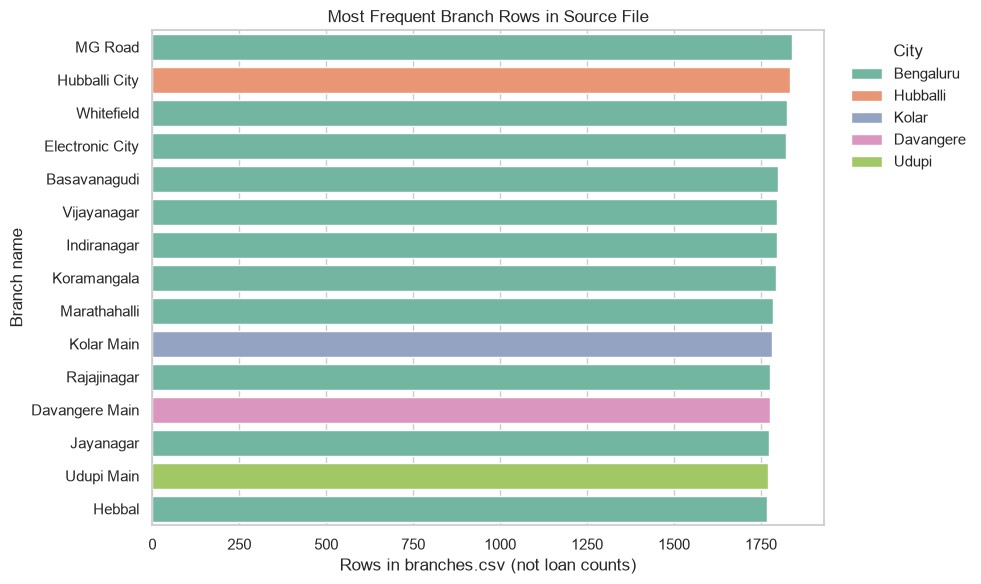

In [ ]:
branch_directory = branches[['branch_id', 'branch_name', 'city']].drop_duplicates()
branch_row_counts = (branches.groupby(['branch_id', 'branch_name', 'city'], observed=True)
                     .size().rename('source_row_count').reset_index()
                     .sort_values('source_row_count', ascending=False))
branch_id_variants = (branches.groupby('branch_id', observed=True)
                      .agg(branch_name_count=('branch_name', 'nunique'),
                           city_count=('city', 'nunique'))
                      .query('branch_name_count > 1 or city_count > 1'))
print(f'Branch source rows: {len(branches)}')
print(f'Unique branch IDs: {branches["branch_id"].nunique()}')
print(f'Unique branch ID/name/city combinations: {len(branch_directory)}')
print(f'Unique cities: {branches["city"].nunique()}')
print('Branch IDs associated with multiple names or cities:')
display(branch_id_variants)
display(branch_row_counts.head(15))

plt.figure(figsize=(10, 6))
top_branch_rows = branch_row_counts.head(15)
sns.barplot(data=top_branch_rows, x='source_row_count', y='branch_name', hue='city', dodge=False)
plt.title('Most Frequent Branch Rows in Source File')
plt.xlabel('Rows in branches.csv (not loan counts)')
plt.ylabel('Branch name')
plt.legend(title='City', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 9. Relationships and Correlation Analysis

Compare loan size, pricing, term, borrower income, credit score, and estimated affordability measures. Use Spearman correlation to summarize monotonic associations and avoid implying causation.

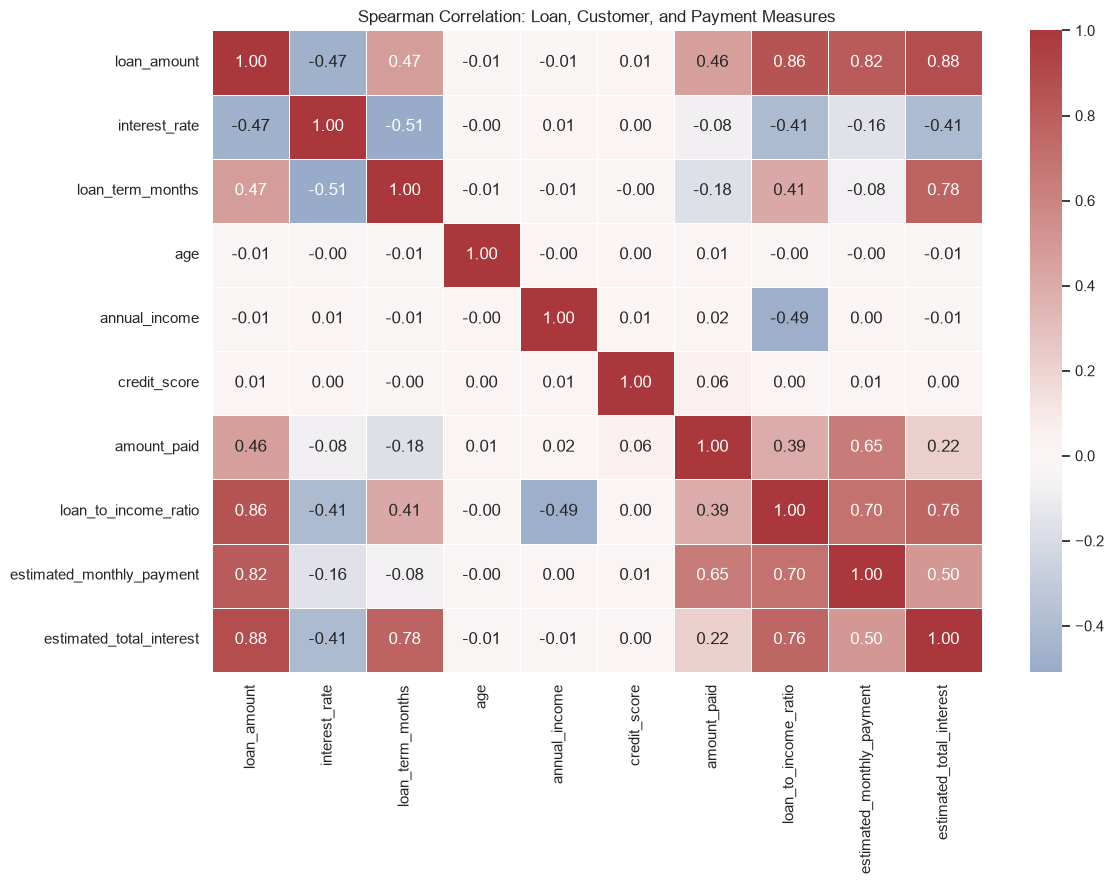

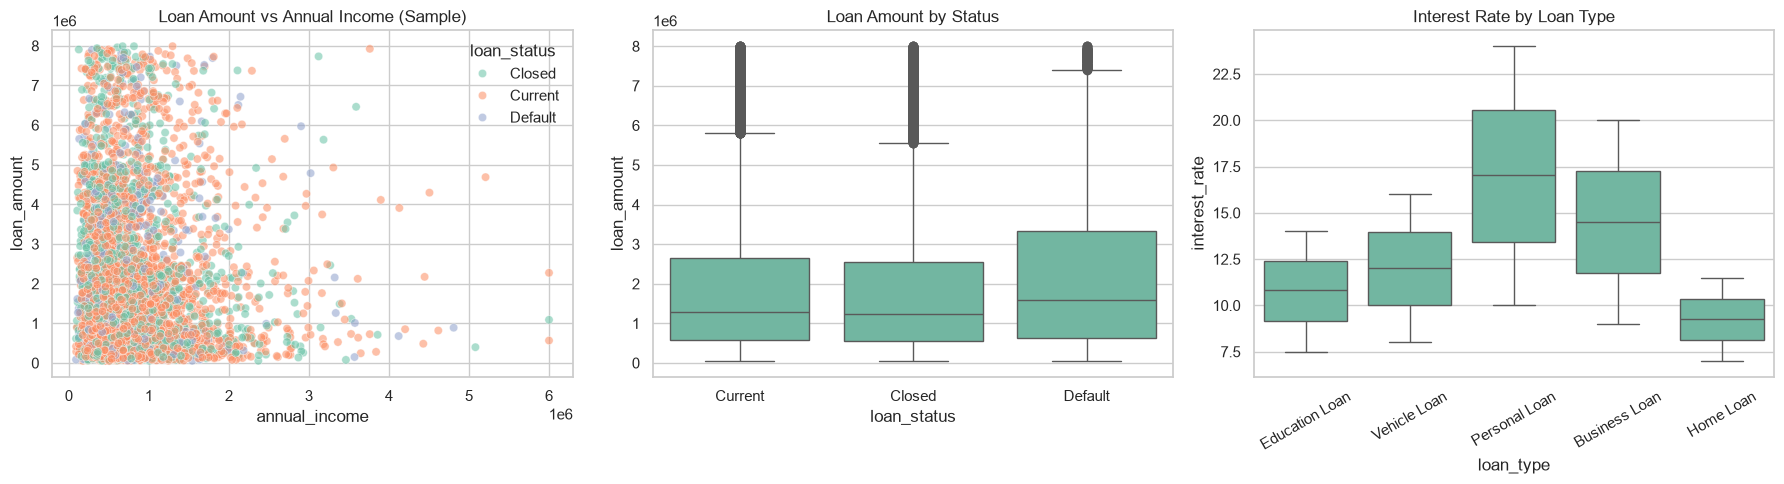

Strongest absolute Spearman associations (excluding the diagonal):


,variable_1,variable_2,spearman_r
9,loan_amount,estimated_total_interest,0.884
7,loan_amount,loan_to_income_ratio,0.857
8,loan_amount,estimated_monthly_payment,0.815
29,loan_term_months,estimated_total_interest,0.778
79,loan_to_income_ratio,estimated_total_interest,0.761
78,loan_to_income_ratio,estimated_monthly_payment,0.699
68,amount_paid,estimated_monthly_payment,0.646
12,interest_rate,loan_term_months,-0.508
89,estimated_monthly_payment,estimated_total_interest,0.504
47,annual_income,loan_to_income_ratio,-0.490


In [21]:
correlation_columns = [
    'loan_amount', 'interest_rate', 'loan_term_months', 'age',
    'annual_income', 'credit_score', 'amount_paid',
    'loan_to_income_ratio', 'estimated_monthly_payment',
    'estimated_total_interest'
]
spearman_corr = loan_analysis[correlation_columns].corr(method='spearman')
plt.figure(figsize=(12, 9))
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='vlag', center=0, linewidths=0.5)
plt.title('Spearman Correlation: Loan, Customer, and Payment Measures')
plt.tight_layout()
plt.show()

sample_size = min(5000, len(loan_analysis))
plot_sample = loan_analysis.sample(sample_size, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=plot_sample, x='annual_income', y='loan_amount', hue='loan_status', alpha=0.55, ax=axes[0])
axes[0].set_title('Loan Amount vs Annual Income (Sample)')
sns.boxplot(data=loan_analysis, x='loan_status', y='loan_amount', ax=axes[1])
axes[1].set_title('Loan Amount by Status')
sns.boxplot(data=loan_analysis, x='loan_type', y='interest_rate', ax=axes[2])
axes[2].set_title('Interest Rate by Loan Type')
axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

print('Strongest absolute Spearman associations (excluding the diagonal):')
correlation_pairs = (spearman_corr.where(np.triu(np.ones(spearman_corr.shape), k=1).astype(bool))
                     .stack().rename('spearman_r').reset_index())
correlation_pairs.columns = ['variable_1', 'variable_2', 'spearman_r']
display(correlation_pairs.assign(abs_r=correlation_pairs['spearman_r'].abs())
        .sort_values('abs_r', ascending=False).drop(columns='abs_r').head(10).round(3))

## 10. Statistical Comparisons

Use Kruskal-Wallis tests for selected multi-group comparisons because the financial measures may be skewed. A small p-value indicates evidence of group differences, not practical importance or causality; interpret alongside medians and plots.

In [22]:
def kruskal_by_group(frame, value_column, group_column):
    samples = [group[value_column].dropna().to_numpy()
               for _, group in frame.groupby(group_column, observed=True)
               if group[value_column].notna().any()]
    if len(samples) < 2:
        return {'measure': value_column, 'groups': group_column,
                'statistic': np.nan, 'p_value': np.nan}
    result = stats.kruskal(*samples)
    return {'measure': value_column, 'groups': group_column,
            'statistic': result.statistic, 'p_value': result.pvalue}

statistical_results = pd.DataFrame([
    kruskal_by_group(loan_analysis, 'interest_rate', 'loan_type'),
    kruskal_by_group(loan_analysis, 'loan_amount', 'loan_status'),
    kruskal_by_group(loan_analysis, 'credit_score', 'loan_status'),
    kruskal_by_group(loan_analysis, 'loan_to_income_ratio', 'loan_status'),
    kruskal_by_group(loan_analysis.dropna(subset=['payment_status']),
                     'amount_paid', 'payment_status')
])
print('Kruskal-Wallis group comparison results:')
display(statistical_results.round(6))
print('Descriptive medians for context:')
display(loan_analysis.groupby('loan_status', observed=True)[
    ['loan_amount', 'interest_rate', 'credit_score', 'loan_to_income_ratio']
].median().round(2))

Kruskal-Wallis group comparison results:


,measure,groups,statistic,p_value
0,interest_rate,loan_type,28911.492589,0.0
1,loan_amount,loan_status,71.993254,0.0
2,credit_score,loan_status,1369.008665,0.0
3,loan_to_income_ratio,loan_status,228.368098,0.0
4,amount_paid,payment_status,8272.813273,0.0


Descriptive medians for context:


,loan_amount,interest_rate,credit_score,loan_to_income_ratio
loan_status,,,,
Closed,1246398.5,12.32,694.0,1.85
Current,1274660.5,12.25,694.0,1.87
Default,1589895.0,12.33,638.0,2.82


## 11. Matplotlib Portfolio Dashboard

Bring the core portfolio, customer, payment, and standalone branch views together for a compact overview.

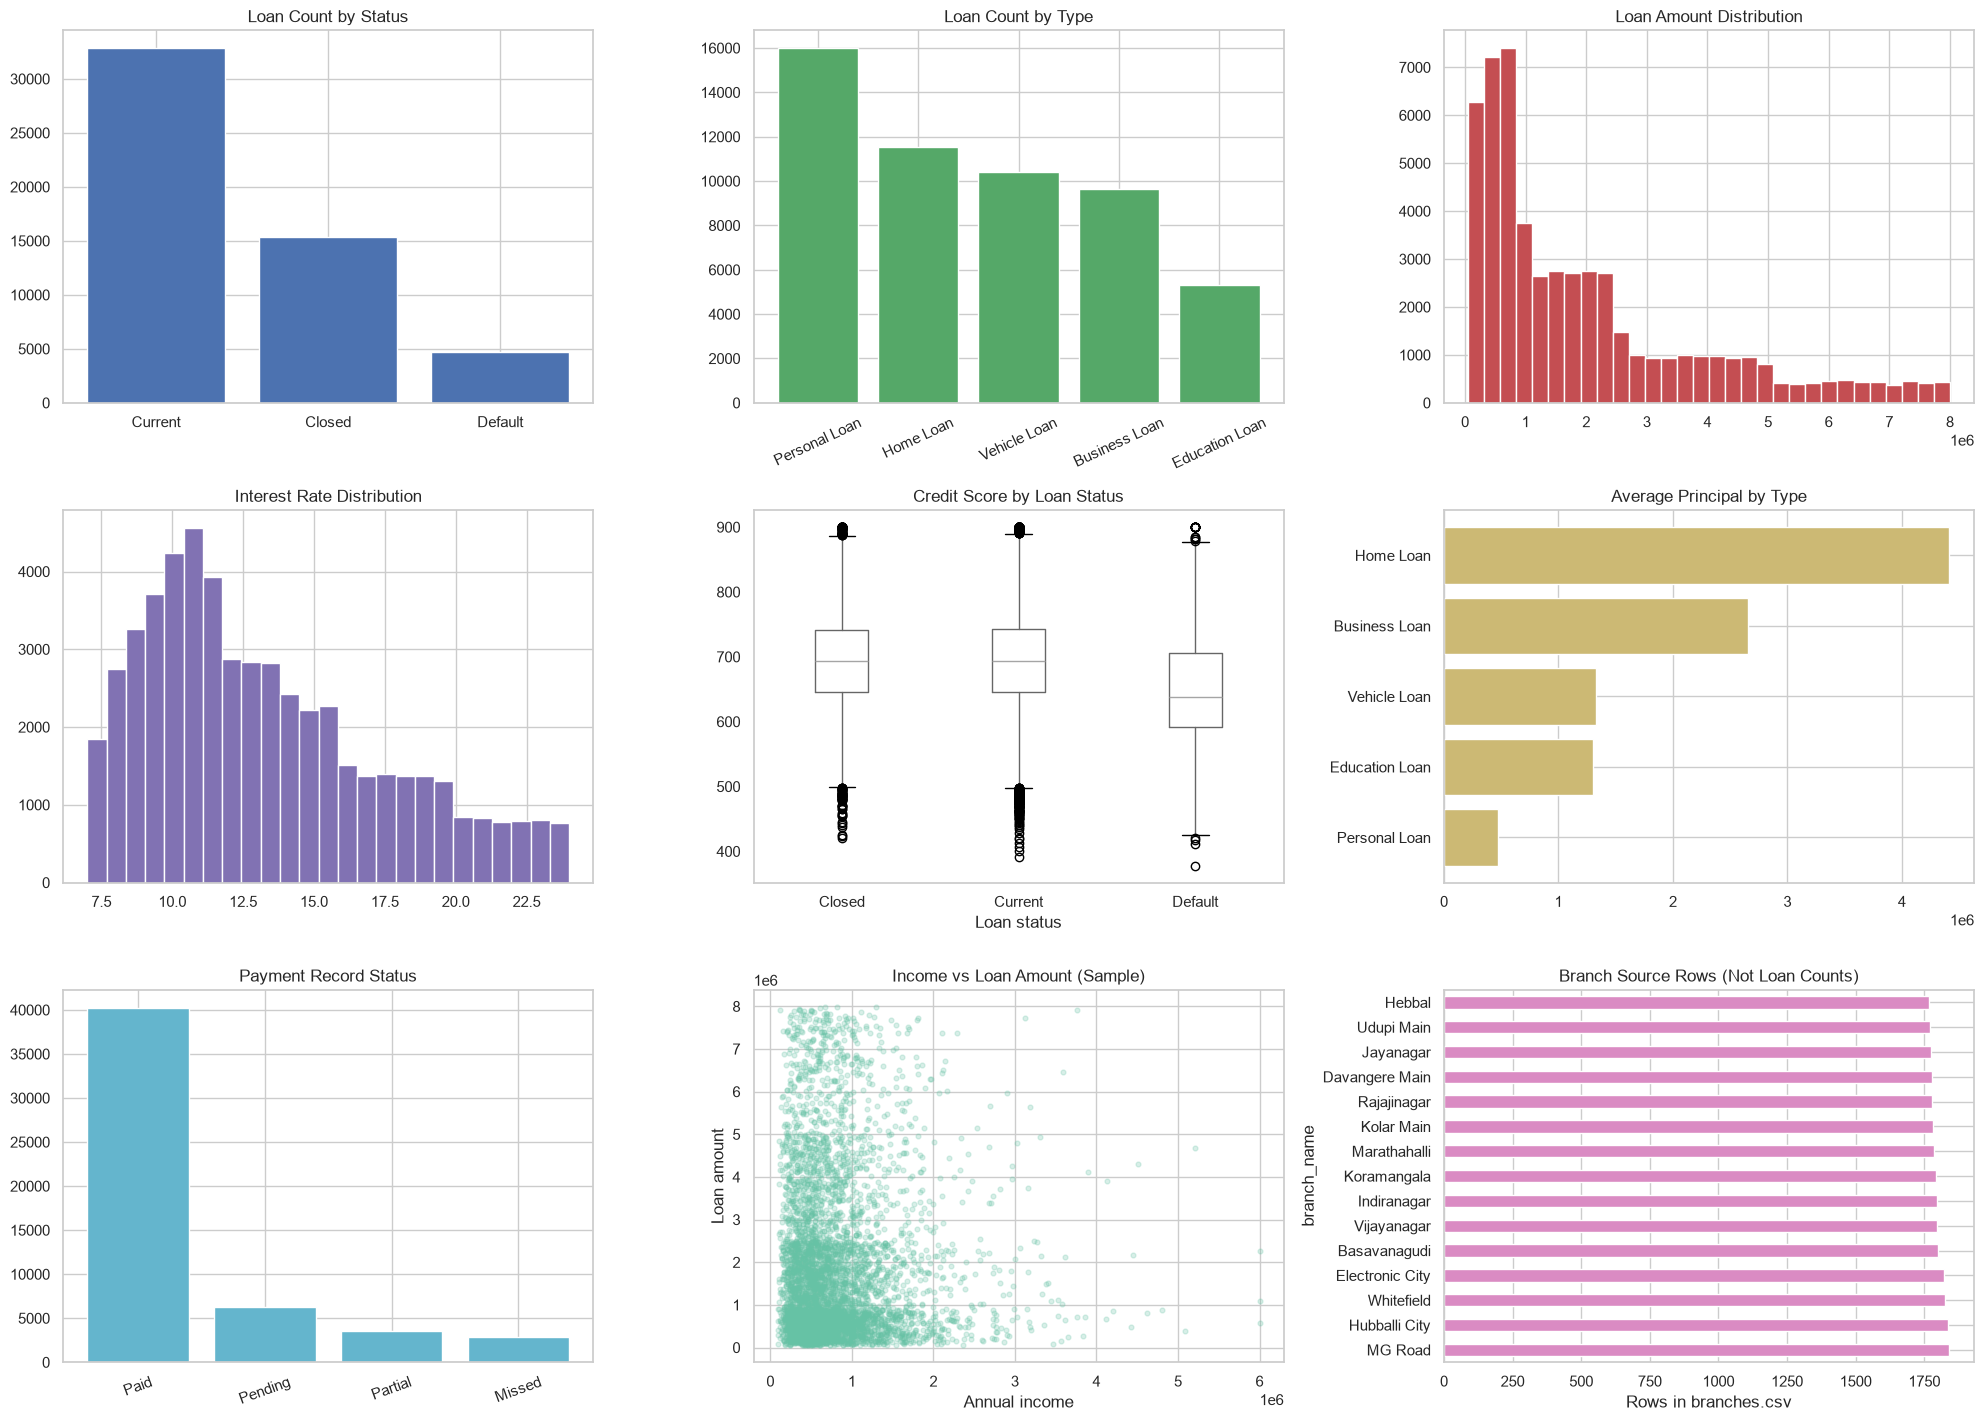

In [23]:
fig, axes = plt.subplots(3, 3, figsize=(20, 15))
fig.suptitle('Loan Portfolio EDA Dashboard', fontsize=20, fontweight='bold')

axes[0, 0].bar(loan_analysis['loan_status'].value_counts().index,
               loan_analysis['loan_status'].value_counts().values, color='#4C72B0')
axes[0, 0].set_title('Loan Count by Status')
axes[0, 1].bar(loan_analysis['loan_type'].value_counts().index,
               loan_analysis['loan_type'].value_counts().values, color='#55A868')
axes[0, 1].set_title('Loan Count by Type')
axes[0, 1].tick_params(axis='x', rotation=25)
axes[0, 2].hist(loan_analysis['loan_amount'], bins=30, color='#C44E52', edgecolor='white')
axes[0, 2].set_title('Loan Amount Distribution')
axes[1, 0].hist(loan_analysis['interest_rate'], bins=25, color='#8172B3', edgecolor='white')
axes[1, 0].set_title('Interest Rate Distribution')
loan_analysis.boxplot(column='credit_score', by='loan_status', ax=axes[1, 1], grid=False)
axes[1, 1].set_title('Credit Score by Loan Status')
axes[1, 1].set_xlabel('Loan status')
axes[1, 1].figure.suptitle('')
average_principal = loan_analysis.groupby('loan_type', observed=True)['loan_amount'].mean().sort_values()
axes[1, 2].barh(average_principal.index, average_principal.values, color='#CCB974')
axes[1, 2].set_title('Average Principal by Type')
payment_counts = payment['payment_status'].value_counts()
axes[2, 0].bar(payment_counts.index, payment_counts.values, color='#64B5CD')
axes[2, 0].set_title('Payment Record Status')
axes[2, 0].tick_params(axis='x', rotation=20)
axes[2, 1].scatter(plot_sample['annual_income'], plot_sample['loan_amount'], alpha=0.25, s=12)
axes[2, 1].set_title('Income vs Loan Amount (Sample)')
axes[2, 1].set_xlabel('Annual income')
axes[2, 1].set_ylabel('Loan amount')
top_branch_rows.plot(kind='barh', x='branch_name', y='source_row_count', ax=axes[2, 2], color='#DA8BC3', legend=False)
axes[2, 2].set_title('Branch Source Rows (Not Loan Counts)')
axes[2, 2].set_xlabel('Rows in branches.csv')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## 12. Seaborn Borrower and Repayment Dashboard

A second dashboard emphasizes distributions and group comparisons using the same validated analytical table.

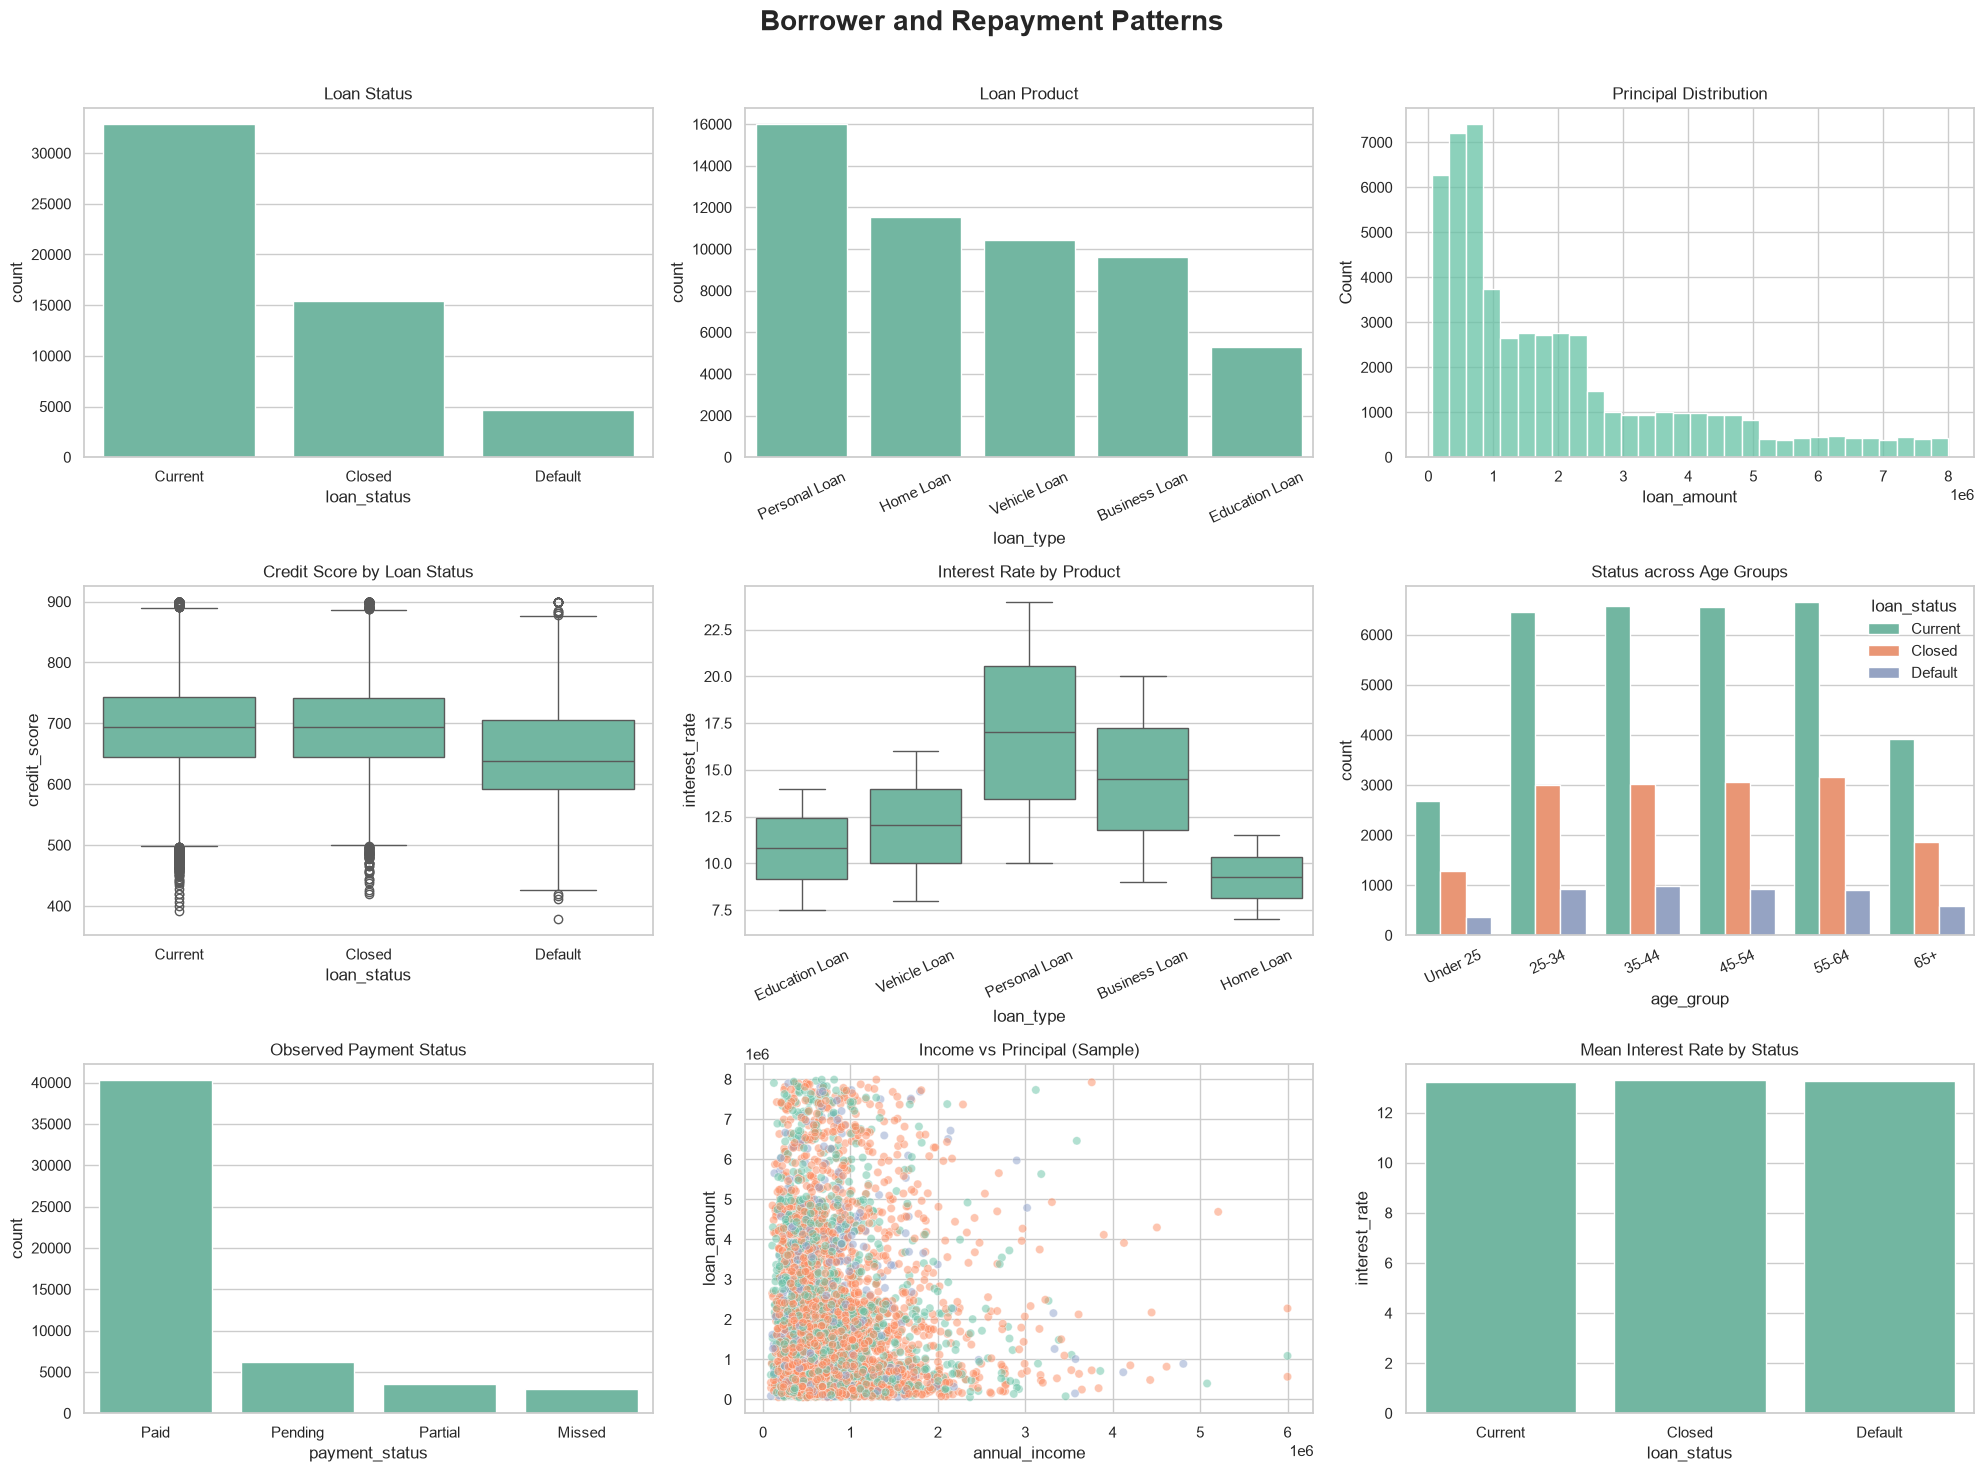

In [24]:
fig, axes = plt.subplots(3, 3, figsize=(20, 15))
fig.suptitle('Borrower and Repayment Patterns', fontsize=20, fontweight='bold')
sns.countplot(data=loan_analysis, x='loan_status', order=loan_analysis['loan_status'].value_counts().index, ax=axes[0, 0])
axes[0, 0].set_title('Loan Status')
sns.countplot(data=loan_analysis, x='loan_type', order=loan_analysis['loan_type'].value_counts().index, ax=axes[0, 1])
axes[0, 1].set_title('Loan Product')
axes[0, 1].tick_params(axis='x', rotation=25)
sns.histplot(data=loan_analysis, x='loan_amount', bins=30, ax=axes[0, 2])
axes[0, 2].set_title('Principal Distribution')
sns.boxplot(data=loan_analysis, x='loan_status', y='credit_score', ax=axes[1, 0])
axes[1, 0].set_title('Credit Score by Loan Status')
sns.boxplot(data=loan_analysis, x='loan_type', y='interest_rate', ax=axes[1, 1])
axes[1, 1].set_title('Interest Rate by Product')
axes[1, 1].tick_params(axis='x', rotation=25)
sns.countplot(data=loan_analysis, x='age_group', hue='loan_status', ax=axes[1, 2])
axes[1, 2].set_title('Status across Age Groups')
axes[1, 2].tick_params(axis='x', rotation=25)
sns.countplot(data=payment, x='payment_status', order=payment['payment_status'].value_counts().index, ax=axes[2, 0])
axes[2, 0].set_title('Observed Payment Status')
sns.scatterplot(data=plot_sample, x='annual_income', y='loan_amount', hue='loan_status', alpha=0.5, ax=axes[2, 1], legend=False)
axes[2, 1].set_title('Income vs Principal (Sample)')
sns.barplot(data=loan_analysis, x='loan_status', y='interest_rate', errorbar=None, ax=axes[2, 2])
axes[2, 2].set_title('Mean Interest Rate by Status')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## 13. Save Visualizations

Export selected portfolio, risk, payment, and correlation charts as PNG files at 300 DPI in a `Visualizations` folder beside the notebook.

In [25]:
OUTPUT_DIR = DATA_DIR / 'Visualizations'
OUTPUT_DIR.mkdir(exist_ok=True)

plt.figure(figsize=(12, 9))
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Spearman Correlation: Loan Portfolio')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '01_spearman_correlation.png', dpi=300, bbox_inches='tight')
plt.close()

plt.figure(figsize=(9, 5))
sns.countplot(data=loan_analysis, x='loan_status', order=loan_analysis['loan_status'].value_counts().index)
plt.title('Loan Count by Status')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '02_loan_status.png', dpi=300, bbox_inches='tight')
plt.close()

plt.figure(figsize=(9, 5))
portfolio_by_type['total_principal'].sort_values().plot(kind='barh', color='#55A868')
plt.title('Total Principal by Loan Type')
plt.xlabel('Total principal')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '03_principal_by_type.png', dpi=300, bbox_inches='tight')
plt.close()

plt.figure(figsize=(9, 5))
sns.histplot(data=loan_analysis, x='loan_amount', bins=35, kde=True)
plt.title('Loan Amount Distribution')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '04_loan_amount_distribution.png', dpi=300, bbox_inches='tight')
plt.close()

plt.figure(figsize=(9, 5))
sns.boxplot(data=loan_analysis, x='loan_status', y='credit_score')
plt.title('Credit Score by Loan Status')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '05_credit_score_by_status.png', dpi=300, bbox_inches='tight')
plt.close()

plt.figure(figsize=(9, 5))
sns.countplot(data=payment, x='payment_status', order=payment['payment_status'].value_counts().index)
plt.title('Observed Payment Record Status')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '06_payment_status.png', dpi=300, bbox_inches='tight')
plt.close()

print(f'Saved {len(list(OUTPUT_DIR.glob("*.png")))} PNG files to: {OUTPUT_DIR.resolve()}')

Saved 6 PNG files to: C:\Users\Adithya\OneDrive\loan_portfolio\Visualizations


## 14. Project Summary and Conclusions

The following outputs are calculated from the loaded files each time the notebook runs, so reported values stay aligned with the current CSV data.

In [26]:
loan_count = len(loan_analysis)
total_principal = loan_analysis['loan_amount'].sum()
leading_status = loan_analysis['loan_status'].value_counts().idxmax()
leading_status_share = loan_analysis['loan_status'].value_counts(normalize=True).iloc[0] * 100
leading_product_count = loan_analysis['loan_type'].value_counts().idxmax()
leading_product_exposure = portfolio_by_type['total_principal'].idxmax()

print('LOAN PORTFOLIO EDA - DATA-DERIVED SUMMARY')
print(f'Loan records: {loan_count:,}')
print(f'Unique customers: {loan_analysis["customer_id"].nunique():,}')
print(f'Total principal in source currency units: {total_principal:,.2f}')
print(f'Median loan amount: {loan_analysis["loan_amount"].median():,.2f}')
print(f'Median interest rate: {loan_analysis["interest_rate"].median():.2f}%')
print(f'Most common loan status: {leading_status} ({leading_status_share:.1f}%)')
print(f'Most common product by loan count: {leading_product_count}')
print(f'Largest product by total principal: {leading_product_exposure}')
print(f'Median customer credit score: {loan_analysis["credit_score"].median():.0f}')
print(f'Payment records: {len(payment):,}; loans without a payment row: {loan_analysis["_payment_merge"].eq("left_only").sum():,}')
print('\nPayment status mix (% of supplied payment rows):')
display((payment['payment_status'].value_counts(normalize=True).mul(100)
         .rename('percent').to_frame().round(2)))
print('Status-level loan characteristics:')
display(status_profile.round(2))
print('Statistical comparisons:')
display(statistical_results.round(6))

print('\nInterpretation guardrails:')
print('- These are descriptive associations from the supplied records, not causal effects or credit decisions.')
print('- Estimated payment and interest features assume fixed-rate monthly amortization and exclude fees.')
print('- The payment file has one row per observed loan in this dataset, not a full installment history.')
print('- Branch rows cannot be assigned to loans because a shared key is absent.')

LOAN PORTFOLIO EDA - DATA-DERIVED SUMMARY
Loan records: 52,899
Unique customers: 52,899
Total principal in source currency units: 104,757,420,870.00
Median loan amount: 1,290,305.00
Median interest rate: 12.28%
Most common loan status: Current (62.1%)
Most common product by loan count: Personal Loan
Largest product by total principal: Home Loan
Median customer credit score: 690
Payment records: 52,898; loans without a payment row: 1

Payment status mix (% of supplied payment rows):


,percent
payment_status,
Paid,76.11
Pending,11.77
Partial,6.67
Missed,5.45


Status-level loan characteristics:


,loan_count,average_loan_amount,median_loan_amount,average_interest_rate,average_credit_score,average_loan_to_income
loan_status,,,,,,
Current,32840,1969280.69,1274660.5,13.23,693.79,3.69
Closed,15384,1935854.63,1246398.5,13.29,693.52,3.68
Default,4675,2204289.91,1589895.0,13.27,650.69,4.86


Statistical comparisons:


,measure,groups,statistic,p_value
0,interest_rate,loan_type,28911.492589,0.0
1,loan_amount,loan_status,71.993254,0.0
2,credit_score,loan_status,1369.008665,0.0
3,loan_to_income_ratio,loan_status,228.368098,0.0
4,amount_paid,payment_status,8272.813273,0.0



Interpretation guardrails:
- These are descriptive associations from the supplied records, not causal effects or credit decisions.
- Estimated payment and interest features assume fixed-rate monthly amortization and exclude fees.
- The payment file has one row per observed loan in this dataset, not a full installment history.
- Branch rows cannot be assigned to loans because a shared key is absent.
